# 03 – Modelling

Project: Developer Salary Prediction  
Data: `data/processed/survey_clean_2025.csv` (7,428 employed professional developers in Europe)

Goal: predict a developer's annual salary from their profile, and find the model with the lowest error.

Plan for this notebook:
- prepare the features based on the EDA in notebook 02,
- split the data and keep the test set aside until the final evaluation,
- compare two simple baselines and four models on a validation set,
- tune the three best models and pick the one with the lowest MAE,
- evaluate the final model once on the test set.

## Setup

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Seed used everywhere, for reproducibility
SEED = 1

sns.set_theme(style="whitegrid")

## Load the data

In [2]:
df = pd.read_csv("../data/processed/survey_clean_2025.csv")

target = "ConvertedCompYearly"
orgsize_order = ["<20", "20-99", "100-499", "500-999", "1,000-4,999", "5,000-9,999", "10,000+"]
age_order = ["18-24", "25-34", "35-44", "45-54", "55+"]

print(df.shape)

(7428, 56)


## Features

Choices from the EDA:
- `WorkExp` is used as log(WorkExp + 1): salary rises fast in the first years and then levels off (B1, T5). Tree models aren't affected by this transformation, so one version works for all models.
- `YearsCode` is dropped (correlation 0.88 with `WorkExp`, F1). Instead I add `coding_before_work` = `YearsCode` − `WorkExp`, the years of coding before working life (negative for career changers).
- `Age` stays: at the same experience it still relates to salary (F2).

In [3]:
# New features
# ------------
df["WorkExp_log"] = np.log1p(df["WorkExp"])
df["coding_before_work"] = df["YearsCode"] - df["WorkExp"]

# Feature groups
# --------------
numeric_cols = ["WorkExp_log", "coding_before_work", "n_languages"]
onehot_cols = ["Country", "DevType", "Industry", "RemoteWork", "ICorPM", "EdLevel"]
ordinal_cols = ["OrgSize", "Age"]
lang_cols = [col for col in df.columns if col.startswith("lang_")]

feature_cols = numeric_cols + onehot_cols + ordinal_cols + ["languages_missing"] + lang_cols

X = df[feature_cols]
y = df[target]

print("Features before encoding:", X.shape[1])
df[["coding_before_work"]].describe().round(1).T

Features before encoding: 54


,count,mean,std,min,25%,50%,75%,max
coding_before_work,7409.0,5.4,4.6,-28.0,3.0,5.0,8.0,30.0


## Train-test split

20% of the data is kept as a test set and stays untouched until the final evaluation. Everything that learns from the data (language selection, fill values, encoder, scaler) is fitted on the training set only.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=SEED)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (5942, 54)
X_test shape:  (1486, 54)


## Language selection

Only languages used by at least 5% of the training set (people with language data) are kept. Rare languages don't give the model enough examples to learn from.

In [5]:
lang_share = X_train.loc[X_train["languages_missing"] == 0, lang_cols].mean()
selected_langs = lang_share[lang_share >= 0.05].index.tolist()

print(f"Languages kept: {len(selected_langs)} of {len(lang_cols)}")
print([col.replace("lang_", "") for col in selected_langs])

Languages kept: 19 of 42
['Bash/Shell', 'C', 'C#', 'C++', 'Go', 'Groovy', 'HTML/CSS', 'Java', 'JavaScript', 'Kotlin', 'Lua', 'PHP', 'PowerShell', 'Python', 'Ruby', 'Rust', 'SQL', 'Swift', 'TypeScript']


## Missing values

- Numeric columns: median of the training set.
- One-hot columns: missing becomes its own category, "unknown".
- Ordered columns (`OrgSize`, `Age`): "unknown" has no place in the order, so the most frequent value of the training set is used.

In [6]:
X_train = X_train.copy()
X_test = X_test.copy()

# Numeric: training median
numeric_medians = X_train[numeric_cols].median()
X_train[numeric_cols] = X_train[numeric_cols].fillna(numeric_medians)
X_test[numeric_cols] = X_test[numeric_cols].fillna(numeric_medians)

# One-hot columns: "unknown" category
X_train[onehot_cols] = X_train[onehot_cols].fillna("unknown")
X_test[onehot_cols] = X_test[onehot_cols].fillna("unknown")

# Ordered columns: most frequent value in training
ordinal_modes = X_train[ordinal_cols].mode().iloc[0]
X_train[ordinal_cols] = X_train[ordinal_cols].fillna(ordinal_modes)
X_test[ordinal_cols] = X_test[ordinal_cols].fillna(ordinal_modes)

print("Missing values left (train / test):", X_train.isnull().sum().sum(), "/", X_test.isnull().sum().sum())
print("\nFill values:")
print(pd.concat([numeric_medians, ordinal_modes]).to_string())

Missing values left (train / test): 0 / 0

Fill values:
WorkExp_log           2.484907
coding_before_work         5.0
n_languages                6.0
OrgSize                  20-99
Age                      25-34


## Encoding

`OrgSize` and `Age` are encoded as ordered numbers, because salary follows their order (B7, B10). `EdLevel` is one-hot encoded together with the other categorical columns, because "Associate" breaks the order (B6).

In [7]:
# Ordinal encoding (fixed order)
# ------------------------------
orgsize_map = {category: i for i, category in enumerate(orgsize_order)}
age_map = {category: i for i, category in enumerate(age_order)}

X_train_ordinal = pd.DataFrame({
    "OrgSize_encoded": X_train["OrgSize"].map(orgsize_map),
    "Age_encoded": X_train["Age"].map(age_map)})
X_test_ordinal = pd.DataFrame({
    "OrgSize_encoded": X_test["OrgSize"].map(orgsize_map),
    "Age_encoded": X_test["Age"].map(age_map)})

# One-hot encoding
# ----------------
encoder = OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore")

# fit + transform on train, transform only on test
X_train_onehot = encoder.fit_transform(X_train[onehot_cols])
X_test_onehot = encoder.transform(X_test[onehot_cols])

onehot_names = encoder.get_feature_names_out(onehot_cols)
X_train_onehot_df = pd.DataFrame(X_train_onehot, columns=onehot_names, index=X_train.index)
X_test_onehot_df = pd.DataFrame(X_test_onehot, columns=onehot_names, index=X_test.index)

print("One-hot columns:", len(onehot_names))

One-hot columns: 63


## Scaling

The numeric and ordinal features are standardized (needed for the linear model; tree models don't depend on it). The 0/1 columns stay as they are.

In [8]:
to_scale_train = pd.concat([X_train[numeric_cols], X_train_ordinal], axis=1)
to_scale_test = pd.concat([X_test[numeric_cols], X_test_ordinal], axis=1)

scaler = StandardScaler()

# fit + transform on train, transform only on test
X_train_scaled = pd.DataFrame(scaler.fit_transform(to_scale_train),
                              columns=to_scale_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(to_scale_test),
                             columns=to_scale_test.columns, index=X_test.index)

## Final feature table

In [9]:
X_train_final = pd.concat([X_train_scaled, X_train_onehot_df,
                           X_train[["languages_missing"] + selected_langs]], axis=1)
X_test_final = pd.concat([X_test_scaled, X_test_onehot_df,
                          X_test[["languages_missing"] + selected_langs]], axis=1)

print(f"X_train_final shape: {X_train_final.shape}")
print(f"X_test_final shape:  {X_test_final.shape}")
print("Missing values:", X_train_final.isnull().sum().sum(), "/", X_test_final.isnull().sum().sum())

X_train_final shape: (5942, 88)
X_test_final shape:  (1486, 88)
Missing values: 0 / 0


## Validation split

The test set stays untouched until the final evaluation, so I compare the models on a validation set: 20% of the training data.

Limitation: the fill values, encoder and scaler were fitted on the whole training set, so they have seen the validation rows. The effect is small, and the test set is completely separate.

In [10]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_final, y_train,
    test_size=0.2,
    random_state=SEED)

print(f"X_tr shape:  {X_tr.shape}")
print(f"X_val shape: {X_val.shape}")

X_tr shape:  (4753, 88)
X_val shape: (1189, 88)


## Evaluation

For every baseline and model I record:
- R² on training and validation (a big gap means overfitting),
- MAE: the average error in USD (main metric),
- RMSE: like MAE, but large errors count more.

Models trained on log salary have their predictions converted back to USD with `np.exp()` before scoring, so all results are comparable.

In [11]:
results = {}

def evaluate(name, y_pred_tr, y_pred_val):
    """Print the scores of one model and store them in results."""
    scores = {
        "R2 (train)": r2_score(y_tr, y_pred_tr),
        "R2 (validation)": r2_score(y_val, y_pred_val),
        "MAE": mean_absolute_error(y_val, y_pred_val),
        "RMSE": mean_squared_error(y_val, y_pred_val) ** 0.5,
    }
    results[name] = scores
    print(f"{name}")
    print(f"  R2 (train):      {scores['R2 (train)'] * 100:.2f}%")
    print(f"  R2 (validation): {scores['R2 (validation)'] * 100:.2f}%")
    print(f"  MAE:  {scores['MAE']:,.0f} USD")
    print(f"  RMSE: {scores['RMSE']:,.0f} USD")

## Baselines

Two simple rules that any model has to beat:
- everyone gets the median salary of the training data,
- everyone gets the median salary of their country. Country is the strongest factor in the EDA, so this rule already captures a lot.

In [12]:
# General median
# --------------
median_salary = y_tr.median()

evaluate("Baseline: general median",
         np.full(len(y_tr), median_salary),
         np.full(len(y_val), median_salary))

Baseline: general median
  R2 (train):      -3.64%
  R2 (validation): -3.18%
  MAE:  32,057 USD
  RMSE: 46,545 USD


In [13]:
# Country median
# --------------
country_tr = X_train.loc[X_tr.index, "Country"]
country_val = X_train.loc[X_val.index, "Country"]

country_medians = y_tr.groupby(country_tr).median()

evaluate("Baseline: country median",
         country_tr.map(country_medians),
         country_val.map(country_medians).fillna(median_salary))

Baseline: country median
  R2 (train):      19.79%
  R2 (validation): 21.94%
  MAE:  27,309 USD
  RMSE: 40,484 USD


## Models

Four models, from simple to complex, each trained on the raw and on the log salary, with default settings (tuning comes later):
- `SGDRegressor`: linear model,
- `DecisionTreeRegressor`: a single tree,
- `RandomForestRegressor`: many trees, averaged,
- `XGBRegressor`: trees built one after another, each fixing the errors of the previous ones.

What I expect from the EDA:
- the country baseline is already much better than the general median,
- the linear model struggles more than the trees, because of the curve in experience and the age × experience interaction,
- a single tree overfits (training R² far above validation R²), and the forest and XGBoost do better.

In [14]:
# SGDRegressor
# ------------
# With the default tol, SGD stopped too early on the log target, before it had learned
# the average log salary. A smaller tol and more iterations let it converge.
sgd_raw = SGDRegressor(loss="squared_error", max_iter=5000, tol=1e-5, random_state=SEED)
sgd_raw.fit(X_tr, y_tr)
evaluate("SGDRegressor (raw)", sgd_raw.predict(X_tr), sgd_raw.predict(X_val))

sgd_log = SGDRegressor(loss="squared_error", max_iter=5000, tol=1e-5, random_state=SEED)
sgd_log.fit(X_tr, np.log(y_tr))
evaluate("SGDRegressor (log)", np.exp(sgd_log.predict(X_tr)), np.exp(sgd_log.predict(X_val)))

SGDRegressor (raw)
  R2 (train):      44.35%
  R2 (validation): 45.05%
  MAE:  23,318 USD
  RMSE: 33,968 USD
SGDRegressor (log)
  R2 (train):      41.14%
  R2 (validation): 42.74%
  MAE:  22,581 USD
  RMSE: 34,676 USD


In [15]:
# Decision Tree
# -------------
tree_raw = DecisionTreeRegressor(random_state=SEED)
tree_raw.fit(X_tr, y_tr)
evaluate("Decision Tree (raw)", tree_raw.predict(X_tr), tree_raw.predict(X_val))

tree_log = DecisionTreeRegressor(random_state=SEED)
tree_log.fit(X_tr, np.log(y_tr))
evaluate("Decision Tree (log)", np.exp(tree_log.predict(X_tr)), np.exp(tree_log.predict(X_val)))

Decision Tree (raw)
  R2 (train):      100.00%
  R2 (validation): -7.30%
  MAE:  31,700 USD
  RMSE: 47,467 USD
Decision Tree (log)
  R2 (train):      100.00%
  R2 (validation): -30.40%
  MAE:  33,174 USD
  RMSE: 52,327 USD


In [16]:
# Random Forest
# -------------
rf_raw = RandomForestRegressor(random_state=SEED)
rf_raw.fit(X_tr, y_tr)
evaluate("Random Forest (raw)", rf_raw.predict(X_tr), rf_raw.predict(X_val))

rf_log = RandomForestRegressor(random_state=SEED)
rf_log.fit(X_tr, np.log(y_tr))
evaluate("Random Forest (log)", np.exp(rf_log.predict(X_tr)), np.exp(rf_log.predict(X_val)))

Random Forest (raw)
  R2 (train):      91.59%
  R2 (validation): 40.30%
  MAE:  23,706 USD
  RMSE: 35,405 USD
Random Forest (log)
  R2 (train):      87.80%
  R2 (validation): 42.03%
  MAE:  22,585 USD
  RMSE: 34,889 USD


In [17]:
# XGBoost
# -------
xgb_raw = XGBRegressor(random_state=SEED)
xgb_raw.fit(X_tr, y_tr)
evaluate("XGBoost (raw)", xgb_raw.predict(X_tr), xgb_raw.predict(X_val))

xgb_log = XGBRegressor(random_state=SEED)
xgb_log.fit(X_tr, np.log(y_tr))
evaluate("XGBoost (log)", np.exp(xgb_log.predict(X_tr)), np.exp(xgb_log.predict(X_val)))

XGBoost (raw)
  R2 (train):      89.35%
  R2 (validation): 39.98%
  MAE:  24,127 USD
  RMSE: 35,502 USD
XGBoost (log)
  R2 (train):      83.08%
  R2 (validation): 41.81%
  MAE:  22,676 USD
  RMSE: 34,954 USD


## Comparison

In [18]:
results_df = pd.DataFrame(results).T.sort_values("MAE")
results_df.style.format({"R2 (train)": "{:.3f}", "R2 (validation)": "{:.3f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}"})

,R2 (train),R2 (validation),MAE,RMSE
SGDRegressor (log),0.411,0.427,"22,581","34,676"
Random Forest (log),0.878,0.420,"22,585","34,889"
XGBoost (log),0.831,0.418,"22,676","34,954"
SGDRegressor (raw),0.444,0.450,"23,318","33,968"
Random Forest (raw),0.916,0.403,"23,706","35,405"
XGBoost (raw),0.894,0.400,"24,127","35,502"
Baseline: country median,0.198,0.219,"27,309","40,484"
Decision Tree (raw),1.000,-0.073,"31,700","47,467"
Baseline: general median,-0.036,-0.032,"32,057","46,545"
Decision Tree (log),1.000,-0.304,"33,174","52,327"


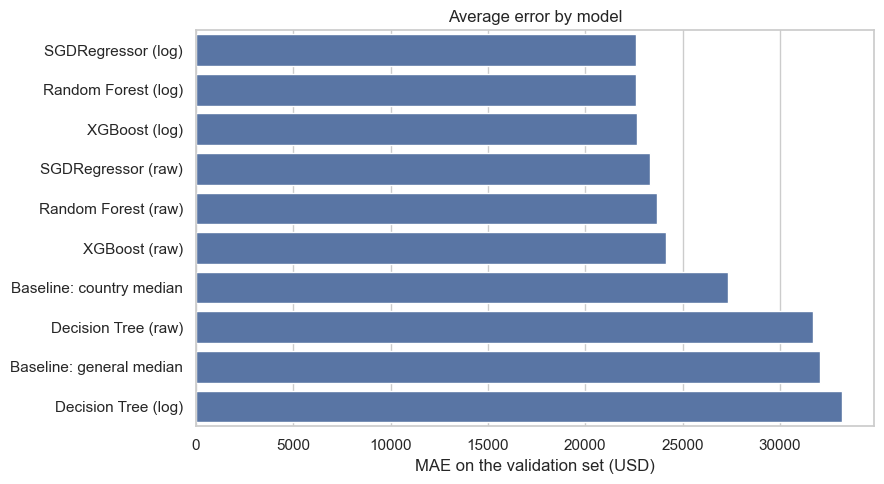

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=results_df["MAE"], y=results_df.index, ax=ax)
ax.set_xlabel("MAE on the validation set (USD)")
ax.set_ylabel("")
ax.set_title("Average error by model")
plt.tight_layout()
plt.savefig("../images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Notes:
- Just using the country median already helps a lot: the MAE goes from 32,057 to 27,309 USD. Country alone explains about 22% of the salary differences, which matches what I saw in the EDA.
- The three best models are basically tied at around 22,600 USD: SGDRegressor, Random Forest and XGBoost, all with the log target. Compared to the country median that's 17% less error, so the other features really add something.
- The log target works better than the raw salary for all three models, so from now on I use log salary.
- I didn't expect the linear model to be this good. I think there are three reasons. First, using log(WorkExp + 1) already takes care of the experience curve. Second, Random Forest and XGBoost overfit with their default settings: R² is around 0.85 on training but only 0.42 on validation. Third, all good models get stuck at about the same R² (0.42 to 0.45). So the limit is probably the data, not the model. Things like city, company or negotiation skills are not in the survey. (Tuning shows this is only part of the story.)
- The single decision tree completely memorizes the training data (R² = 1.0) and does worse than just guessing the median on validation.
- RMSE (about 34,700) is a lot higher than MAE (about 22,600). This means some predictions are very far off, probably for people with high salaries. I'll check this in the error analysis.
- Following my rule (lowest MAE), SGDRegressor with the log target wins, and it's also the simplest model. But the top three are less than 100 USD apart, so with only one validation split this ranking could be luck. That's why I tune all three below.

## Tuning

The top three models were less than 100 USD apart, and that was on just one validation split. So I tune all three and compare them again afterwards.

How I do it:
- I search for the best settings on the training part (`X_tr`) with 4-fold cross-validation, like in the course.
- The search picks the settings with the lowest MAE on the log salary.
- Then I check each tuned model on the validation set in USD, the same way as before, and pick the one with the lowest MAE.

### SGDRegressor

Grid Search tries all 12 combinations. `alpha` controls how strongly the model is kept simple, `penalty` is the type of that control.

In [20]:
# Grid Search over SGDRegressor
# -----------------------------
grid = {
    "alpha": [0.00001, 0.0001, 0.001, 0.01],
    "penalty": ["l2", "l1", "elasticnet"]}

sgd = SGDRegressor(loss="squared_error", max_iter=5000, tol=1e-5, random_state=SEED)

sgd_search = GridSearchCV(estimator=sgd, param_grid=grid, cv=4,
                          scoring="neg_mean_absolute_error", n_jobs=-1)
sgd_search.fit(X_tr, np.log(y_tr))

print("Best settings:", sgd_search.best_params_)

Best settings: {'alpha': 0.01, 'penalty': 'l2'}


In [21]:
# Results
# -------
best_sgd = sgd_search.best_estimator_

evaluate("SGDRegressor (log, tuned)",
         np.exp(best_sgd.predict(X_tr)),
         np.exp(best_sgd.predict(X_val)))

SGDRegressor (log, tuned)
  R2 (train):      40.48%
  R2 (validation): 43.07%
  MAE:  22,326 USD
  RMSE: 34,575 USD


### Random Forest

Grid Search tries all 18 combinations. The default forest overfit a lot, so the most important setting here is `min_samples_leaf`: the higher it is, the less the trees can memorize single people. `max_features` = 0.33 is the "one third of the features" rule from the course.

In [22]:
# Grid Search over Random Forest
# ------------------------------
grid = {
    "n_estimators": [100, 300],
    "min_samples_leaf": [1, 5, 10],
    "max_features": [0.33, "sqrt", 1.0]}

rf = RandomForestRegressor(random_state=SEED)

rf_search = GridSearchCV(estimator=rf, param_grid=grid, cv=4,
                         scoring="neg_mean_absolute_error", n_jobs=-1)
rf_search.fit(X_tr, np.log(y_tr))

print("Best settings:", rf_search.best_params_)

Best settings: {'max_features': 0.33, 'min_samples_leaf': 1, 'n_estimators': 300}


In [23]:
# Results
# -------
best_rf = rf_search.best_estimator_

evaluate("Random Forest (log, tuned)",
         np.exp(best_rf.predict(X_tr)),
         np.exp(best_rf.predict(X_val)))

Random Forest (log, tuned)
  R2 (train):      87.87%
  R2 (validation): 42.75%
  MAE:  22,175 USD
  RMSE: 34,671 USD


### XGBoost

XGBoost has many settings, so trying every combination would take too long. Random Search tries 20 random combinations instead. I added `max_depth` to the settings from the course, because limiting how deep the trees grow is the most direct way to fight overfitting.

In [24]:
# Random Search over XGBoost
# --------------------------
grid = {
    "n_estimators": [300, 500, 700, 1000],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [3, 4, 6],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [1, 3, 10, 20]}

xgb = XGBRegressor(random_state=SEED)

xgb_search = RandomizedSearchCV(estimator=xgb, param_distributions=grid, n_iter=20, cv=4,
                                scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1)
xgb_search.fit(X_tr, np.log(y_tr))

print("Best settings:", xgb_search.best_params_)

Best settings: {'subsample': 0.7, 'reg_lambda': 3, 'n_estimators': 700, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


In [25]:
# Results
# -------
best_xgb = xgb_search.best_estimator_

evaluate("XGBoost (log, tuned)",
         np.exp(best_xgb.predict(X_tr)),
         np.exp(best_xgb.predict(X_val)))

XGBoost (log, tuned)
  R2 (train):      56.35%
  R2 (validation): 48.00%
  MAE:  21,155 USD
  RMSE: 33,044 USD


### Before and after tuning

The gap column is R² on training minus R² on validation. A big gap means the model memorizes the training data.

In [26]:
before_after = pd.DataFrame(results).T.loc[[
    "SGDRegressor (log)", "SGDRegressor (log, tuned)",
    "Random Forest (log)", "Random Forest (log, tuned)",
    "XGBoost (log)", "XGBoost (log, tuned)"]]

before_after["R2 gap"] = before_after["R2 (train)"] - before_after["R2 (validation)"]

before_after.style.format({"R2 (train)": "{:.3f}", "R2 (validation)": "{:.3f}",
                           "MAE": "{:,.0f}", "RMSE": "{:,.0f}", "R2 gap": "{:.3f}"})

,R2 (train),R2 (validation),MAE,RMSE,R2 gap
SGDRegressor (log),0.411,0.427,"22,581","34,676",-0.016
"SGDRegressor (log, tuned)",0.405,0.431,"22,326","34,575",-0.026
Random Forest (log),0.878,0.420,"22,585","34,889",0.458
"Random Forest (log, tuned)",0.879,0.428,"22,175","34,671",0.451
XGBoost (log),0.831,0.418,"22,676","34,954",0.413
"XGBoost (log, tuned)",0.564,0.480,"21,155","33,044",0.084


In [27]:
# Tuned models, best first
before_after.loc[["SGDRegressor (log, tuned)", "Random Forest (log, tuned)",
                  "XGBoost (log, tuned)"]].sort_values("MAE")[["MAE", "RMSE", "R2 (validation)", "R2 gap"]].round(3)

,MAE,RMSE,R2 (validation),R2 gap
"XGBoost (log, tuned)",21154.988,33044.166,0.480,0.084
"Random Forest (log, tuned)",22174.710,34671.200,0.428,0.451
"SGDRegressor (log, tuned)",22325.660,34574.723,0.431,-0.026


Notes:
- SGDRegressor gets a little better after tuning (22,581 to 22,326 USD). It didn't overfit before, so there wasn't much to improve.
- Random Forest also gets a little better (22,585 to 22,175 USD), but it still overfits just as much (gap 0.45). Grid Search only looks at the validation score, so it picked settings that still let the trees memorize. This is the same thing the course warned about.
- XGBoost changes the most: the MAE drops by about 1,500 USD to 21,155, R² on validation goes up to 0.48 and the gap falls from 0.41 to 0.08. The chosen settings (shallow trees with max_depth 3, a small learning rate, each tree seeing only part of the data) stop it from memorizing. Adding max_depth to the course settings paid off.
- Before tuning I thought all models were stuck at the same R² because of the data. XGBoost now goes beyond that, so part of the limit was overfitting. Shallow trees can capture combinations of up to three features, like age and experience together, which the linear model can't.
- Following my rule (lowest MAE), tuned XGBoost with the log target is the final model. This time the gap to the second model is about 1,000 USD, so it's a clear choice. It's also the best on all four metrics, so the choice doesn't depend on which metric I look at.

## Final model

The comparison is done, so the validation set has no job anymore. I train the final model with the best XGBoost settings on the whole training set (training + validation), so it learns from about 25% more data.

In [28]:
final_model = XGBRegressor(**xgb_search.best_params_, random_state=SEED)
final_model.fit(X_train_final, np.log(y_train))

print("Final settings:", xgb_search.best_params_)

Final settings: {'subsample': 0.7, 'reg_lambda': 3, 'n_estimators': 700, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


## Test set results

This is the first and only time I use the test set. I also score the two baselines on it, with medians from the whole training set.

In [29]:
def scores(y_true, y_pred):
    """R2, MAE and RMSE of one set of predictions."""
    return {"R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5}

# Predictions of the final model, back in USD
y_pred_train = np.exp(final_model.predict(X_train_final))
y_pred_test = np.exp(final_model.predict(X_test_final))

# Baselines, with medians from the whole training set
median_all = y_train.median()
country_medians_all = y_train.groupby(X_train["Country"]).median()
country_pred_test = X_test["Country"].map(country_medians_all).fillna(median_all)

test_results = pd.DataFrame({
    "Baseline: general median": scores(y_test, np.full(len(y_test), median_all)),
    "Baseline: country median": scores(y_test, country_pred_test),
    "XGBoost (log, tuned)": scores(y_test, y_pred_test)}).T

print(f"Final model R2 (train): {r2_score(y_train, y_pred_train) * 100:.2f}%")
print(f"Final model R2 (test):  {r2_score(y_test, y_pred_test) * 100:.2f}%\n")

test_results.style.format({"R2": "{:.3f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}"})

Final model R2 (train): 55.42%
Final model R2 (test):  39.33%



,R2,MAE,RMSE
Baseline: general median,-0.029,"31,698","47,582"
Baseline: country median,0.139,"27,510","43,508"
"XGBoost (log, tuned)",0.393,"21,462","36,527"


Notes:
- On the test set the MAE is 21,462 USD, almost the same as on the validation set (21,155). So the model keeps its performance on data it has never seen, and the model choice wasn't just luck on one split.
- Compared to the baselines, the error is 32% lower than the general median and 22% lower than the country median (27,510 USD).
- R² drops more, from 0.48 on validation to 0.39 on test. But the baselines drop too (country median from 0.22 to 0.14), and RMSE goes up (33,044 to 36,527). So the test set seems to have a few people with very large errors, probably high earners. R² reacts strongly to those, MAE much less. This is one more reason why MAE is my main metric.
- The gap between training (55%) and test R² (39%) is about 16 points. The model still memorizes a bit, but much less than XGBoost before tuning.

## Error analysis

Where is the model most wrong? I look at two kinds of error. MAE in USD, as before. And the median percentage error (error ÷ real salary), because the same error in USD means very different things in different countries: 15,000 USD is about 11% of a typical salary in Switzerland, but about 33% in Greece. With MAE alone, high-paying countries would always look worse. I use the median because a few very low salaries would blow up the average.

In [30]:
errors = pd.DataFrame({"actual": y_test, "predicted": y_pred_test})
errors["abs_error"] = (errors["actual"] - errors["predicted"]).abs()
errors["pct_error"] = errors["abs_error"] / errors["actual"] * 100

# Groups to compare
errors["salary_band"] = pd.cut(errors["actual"],
                               bins=[0, 40_000, 60_000, 80_000, 100_000, 150_000, 500_000],
                               labels=["<40k", "40-60k", "60-80k", "80-100k", "100-150k", "150k+"])
errors["Country"] = X_test["Country"]
errors["DevType"] = X_test["DevType"]
errors["experience"] = pd.cut(df.loc[X_test.index, "WorkExp"],
                              bins=[-1, 2, 5, 10, 15, 20, 30, 50],
                              labels=["0-2", "3-5", "6-10", "11-15", "16-20", "21-30", "31+"])


def error_table(col):
    """Number of people, MAE and median percentage error per group."""
    return errors.groupby(col, observed=True).agg(
        count=("abs_error", "size"),
        MAE=("abs_error", "mean"),
        median_pct_error=("pct_error", "median")).round(0)

### Predicted vs real salary

Points on the red line are perfect predictions. Both axes use a log scale.

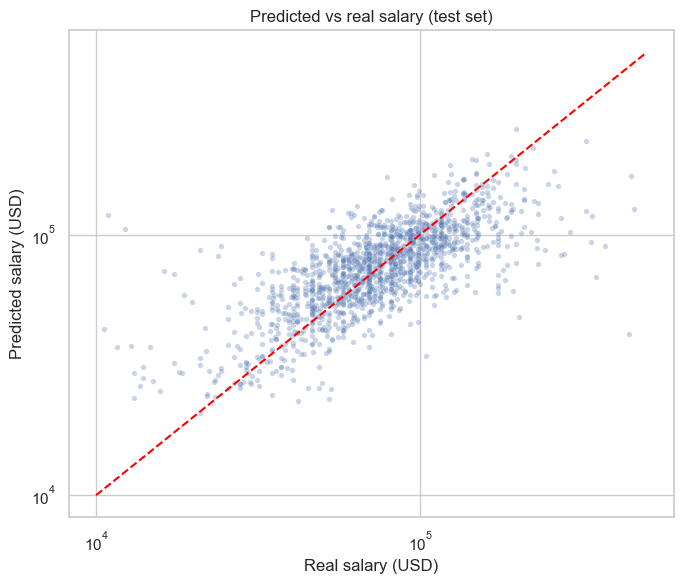

In [31]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=errors, x="actual", y="predicted", alpha=0.3, s=15, ax=ax)
ax.plot([10_000, 500_000], [10_000, 500_000], color="red", linestyle="--")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Real salary (USD)")
ax.set_ylabel("Predicted salary (USD)")
ax.set_title("Predicted vs real salary (test set)")
plt.tight_layout()
plt.show()

### By salary level

In [32]:
error_table("salary_band")

,count,MAE,median_pct_error
salary_band,,,
<40k,151,16071.0,38.0
40-60k,316,14782.0,23.0
60-80k,346,13820.0,16.0
80-100k,294,14776.0,14.0
100-150k,273,24353.0,18.0
150k+,106,85106.0,36.0


### By country

In [33]:
error_table("Country").sort_values("median_pct_error")

,count,MAE,median_pct_error
Country,,,
Finland,30,13482.0,9.0
Sweden,71,14983.0,14.0
Denmark,33,17159.0,14.0
Switzerland,56,24629.0,15.0
Belgium,25,16536.0,17.0
Czech Republic,35,16558.0,18.0
France,140,16392.0,18.0
Germany,282,21224.0,18.0
Other Western & Southern Europe,10,21601.0,18.0


### By experience

In [34]:
error_table("experience")

,count,MAE,median_pct_error
experience,,,
0-2,105,11289.0,18.0
3-5,225,14571.0,18.0
6-10,413,19236.0,19.0
11-15,292,26243.0,21.0
16-20,167,26904.0,20.0
21-30,218,24252.0,19.0
31+,66,30942.0,25.0


### By role

In [35]:
error_table("DevType").sort_values("median_pct_error")

,count,MAE,median_pct_error
DevType,,,
Architect,112,23509.0,17.0
Full-stack developer,498,18494.0,17.0
Front-end developer,72,22210.0,18.0
Embedded developer,84,20732.0,19.0
Back-end developer,296,21929.0,20.0
Data & AI,92,22453.0,20.0
Mobile developer,50,27065.0,21.0
DevOps & infrastructure,71,21572.0,22.0
Other,33,25293.0,22.0


Notes:
- The model gets the general direction right, but it pulls predictions toward the middle: low salaries are predicted too high, high salaries too low. It can't see things like the company or negotiation skills, so it predicts the typical salary for a profile.
- Errors are lowest for 60,000 to 100,000 USD (14 to 16%) and highest at both ends (about 37%). The 7% of people earning over 150,000 USD cause about 28% of the total error.
- By country, MAE alone is misleading: Switzerland has a higher MAE than Greece, but a lower percentage error (15% vs 22%). The model works best in the Nordic countries and worst in Eastern and Southern Europe. For the Netherlands the typical error is about 20%.
- By experience and role the percentage error is fairly even (mostly 17 to 23%). Mixed groups like "Management" and "Other developer" are a bit harder to predict.
- Overall: most reliable for typical developers (about two thirds of the test set), least reliable for very high or very low salaries.

## Feature importance

Which features does the final model rely on most? First the single columns. Then I add up the columns that belong to the same feature (e.g. all `Country_...` columns), so I can compare the result with the EDA.

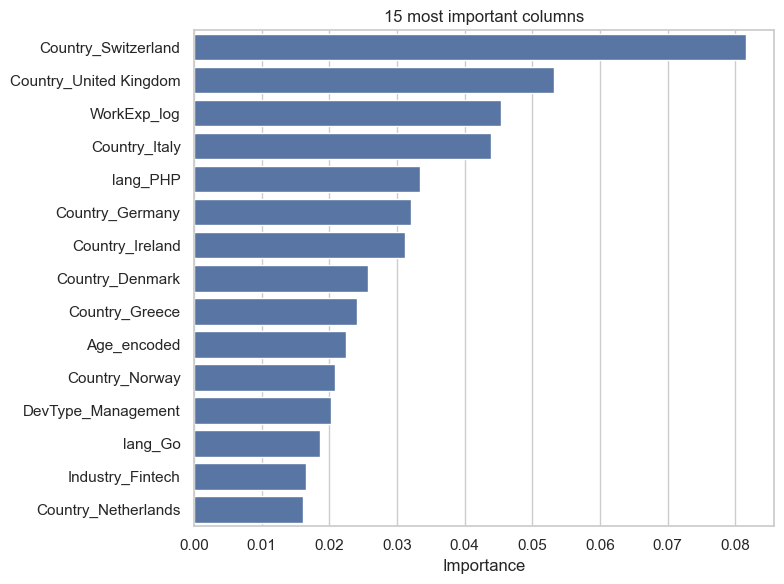

In [36]:
importance = pd.Series(final_model.feature_importances_,
                       index=X_train_final.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=importance.head(15).values, y=importance.head(15).index, ax=ax)
ax.set_xlabel("Importance")
ax.set_ylabel("")
ax.set_title("15 most important columns")
plt.tight_layout()
plt.show()

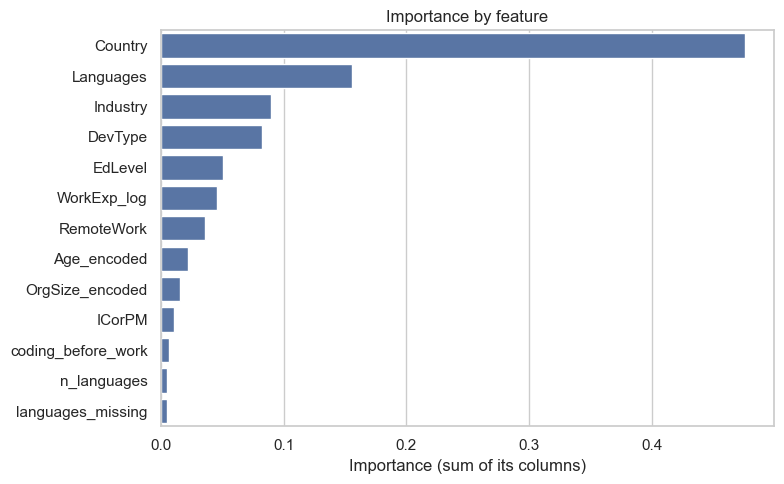

Country               0.476
Languages             0.156
Industry              0.090
DevType               0.082
EdLevel               0.051
WorkExp_log           0.045
RemoteWork            0.036
Age_encoded           0.022
OrgSize_encoded       0.015
ICorPM                0.011
coding_before_work    0.006
n_languages           0.005
languages_missing     0.005
dtype: float32

In [37]:
# Group the columns back into the original features
# -------------------------------------------------
def original_feature(col):
    for feature in onehot_cols:
        if col.startswith(feature + "_"):
            return feature
    if col.startswith("lang_"):
        return "Languages"
    return col

importance_by_feature = (importance.groupby(importance.index.map(original_feature))
                         .sum().sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=importance_by_feature.values, y=importance_by_feature.index, ax=ax)
ax.set_xlabel("Importance (sum of its columns)")
ax.set_ylabel("")
ax.set_title("Importance by feature")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importance_by_feature.round(3)

Notes:
- Country is by far the most important feature (about half of the total importance), which confirms the main finding of the EDA. The most important single columns are countries at the top and bottom of the salary ranking (Switzerland, Italy, Greece) and the biggest groups (UK, Germany).
- The other top columns also match the EDA: work experience, age, PHP and Go, management roles and fintech.
- The ranking after country has to be read with care. A feature's importance is the sum of its columns, so features with many columns look bigger: Languages has 19 columns, work experience only one. Experience is also split over three features (WorkExp_log, Age, coding_before_work); together they reach about 0.07, third place.
- The number of languages is barely used (0.005), as expected from B11. My extra feature coding_before_work also adds very little (0.006): WorkExp and Age already carry most of that information.

## Save the model

I save the final model and everything needed to prepare new data the same way (fill values, maps, encoder, scaler, language list, column order). With these files, a future app can predict a salary without training the model again.

In [38]:
os.makedirs("../models", exist_ok=True)

joblib.dump(final_model, "../models/xgb_final_model.joblib")

preprocessing = {
    "numeric_cols": numeric_cols,
    "onehot_cols": onehot_cols,
    "numeric_medians": numeric_medians,
    "ordinal_modes": ordinal_modes,
    "orgsize_map": orgsize_map,
    "age_map": age_map,
    "encoder": encoder,
    "scaler": scaler,
    "selected_langs": selected_langs,
    "final_columns": list(X_train_final.columns),
}
joblib.dump(preprocessing, "../models/preprocessing.joblib")

for file in os.listdir("../models"):
    print(f"{file}: {os.path.getsize('../models/' + file) / 1_000_000:.2f} MB")

preprocessing.joblib: 0.01 MB
xgb_final_model.joblib: 0.83 MB


## Summary

- Final model: XGBoost trained on log salary, tuned with Random Search (shallow trees, max_depth 3).
- On the test set it is off by 21,462 USD on average (MAE), 22% less than just using the median salary of each country. It explains about 39% of the salary differences.
- Country is by far the most important feature, followed by experience, role, industry and education, in line with the EDA.
- It works best for typical developers (40,000 to 100,000 USD) and in the Nordic countries, and worst for very high or very low salaries and in Eastern and Southern Europe.
- Limits: self-reported survey data, only employed developers in Europe, and important factors like the company, city or negotiation skills are not in the data.

## Next steps
- README: project summary, results and how to run the notebooks
- Slides for the presentation
- Later: a small salary calculator app using the saved model